Урок в прозе: https://proproprogs.ru/nn_pytorch/pytorch-vvedenie-v-avtoenkodery

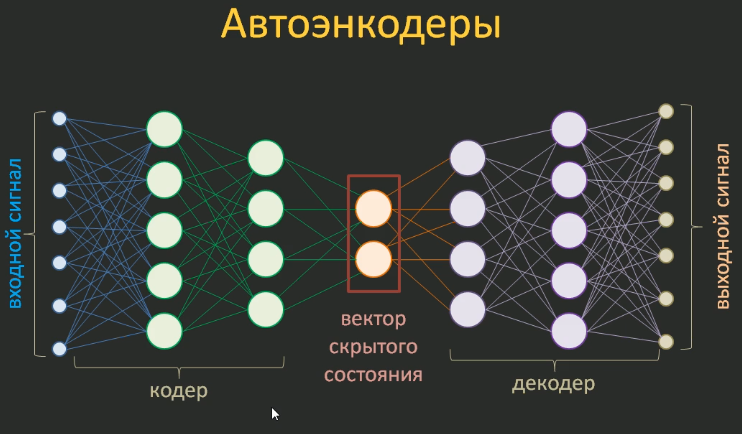

Можно на вход подавать и последовательности

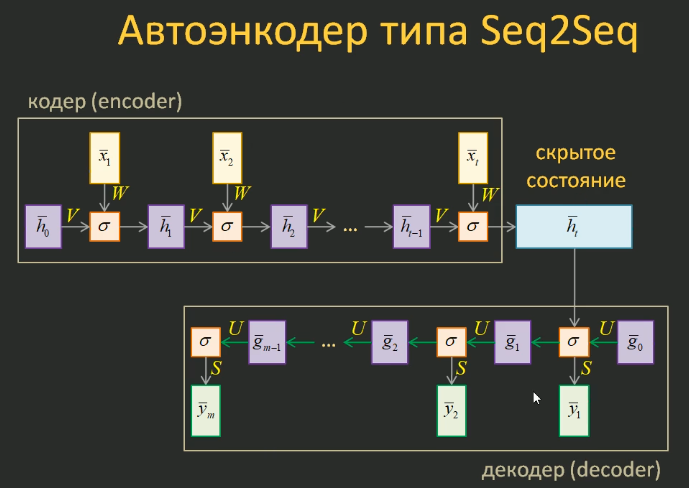

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

from tqdm import tqdm
import torch
import torch.utils.data as data
import torchvision
import torchvision.transforms.v2 as tfs_v2
import torch.nn as nn
import torch.optim as optim

class AutoEncoderMNIST(nn.Module):
    def __init__(self, input_dim, output_dim, hidden_dim):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ELU(inplace=True),
            nn.Linear(128, 64),
            nn.ELU(inplace=True),
            nn.Linear(64, self.hidden_dim)
        )
 
        self.decoder = nn.Sequential(
            nn.Linear(self.hidden_dim, 64),
            nn.ELU(inplace=True),
            nn.Linear(64, 128),
            nn.ELU(inplace=True),
            nn.Linear(128, output_dim),
            nn.Sigmoid()
        )
 
    def forward(self, x):
        h = self.encoder(x)
        x = self.decoder(h)
 
        return x, h

In [5]:
model = AutoEncoderMNIST(784, 784, 28)
transforms = tfs_v2.Compose([tfs_v2.ToImage(), tfs_v2.ToDtype(dtype=torch.float32, scale=True),
                             tfs_v2.Lambda(lambda _img: _img.ravel())])

d_train = torchvision.datasets.MNIST(r'mnist', download=True, train=True, transform=transforms)
train_data = data.DataLoader(d_train, batch_size=100, shuffle=True)

In [6]:
optimizer = optim.Adam(params=model.parameters(), lr=0.001)
loss_func = nn.MSELoss()

epochs = 5
model.train()

for _e in range(epochs):
    loss_mean = 0
    lm_count = 0

    train_tqdm = tqdm(train_data, leave=True)
    for x_train, y_train in train_tqdm:
        predict, _ = model(x_train)
        loss = loss_func(predict, x_train)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        lm_count += 1
        loss_mean = 1/lm_count * loss.item() + (1 - 1/lm_count) * loss_mean
        train_tqdm.set_description(f"Epoch [{_e+1}/{epochs}], loss_mean={loss_mean:.3f}")

st = model.state_dict()
torch.save(st, 'model_autoencoder.tar')

Epoch [5/5], loss_mean=0.017: 100%|██████████| 600/600 [00:17<00:00, 33.51it/s]


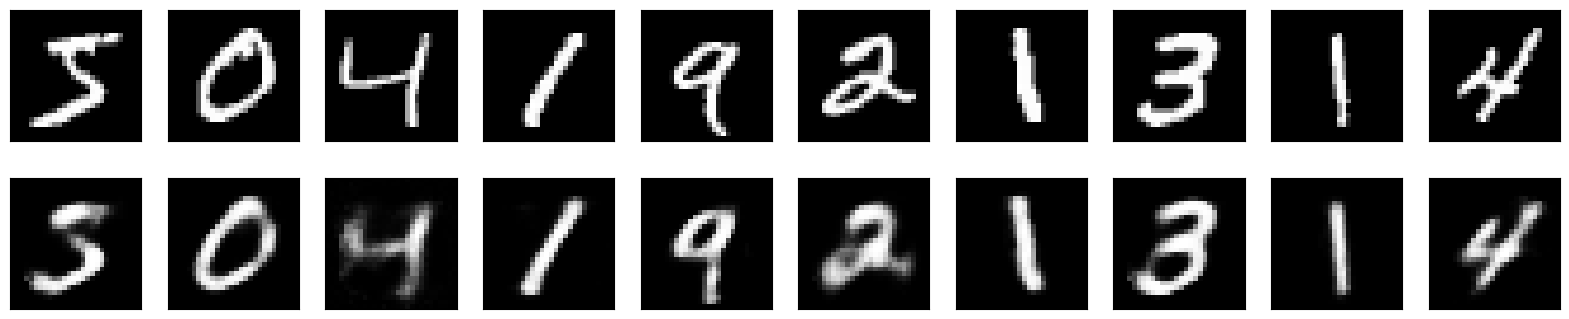

In [7]:
n = 10
model.eval()

plt.figure(figsize=(2*n, 2*2))
for i in range(n):
    img, _ = d_train[i]
    predict, _ = model(img.unsqueeze(0))

    predict = predict.squeeze(0).view(28, 28)
    img = img.view(28, 28)

    dec_img = predict.detach().numpy()
    img = img.detach().numpy()

    ax = plt.subplot(2, n, i+1)
    plt.imshow(img, cmap='gray')
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

    ax2 = plt.subplot(2, n, i+n+1)
    plt.imshow(dec_img, cmap='gray')
    ax2.get_xaxis().set_visible(False)
    ax2.get_yaxis().set_visible(False)

plt.show()

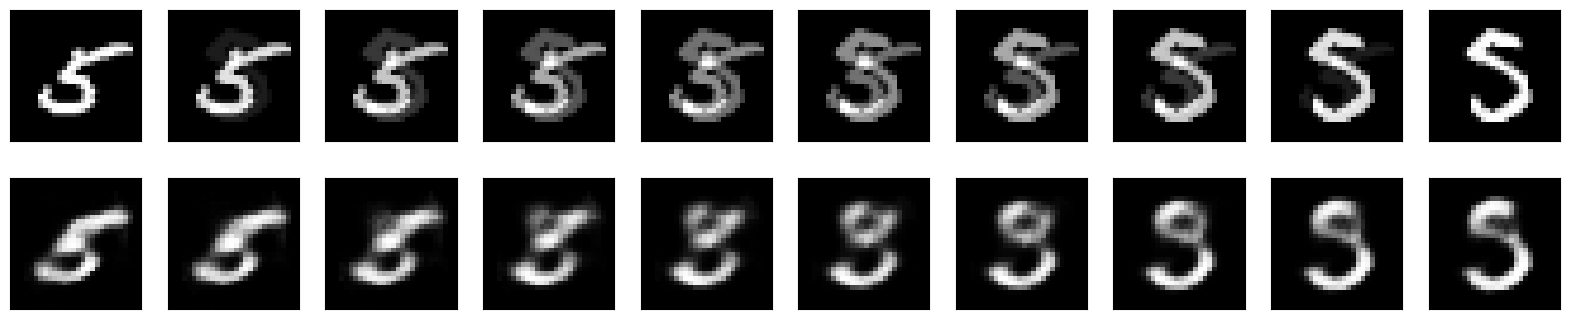

In [8]:
plt.figure(figsize=(2*n, 2*2))

# фрагмент для формирования и отображения гомотопии изображений по прямой
frm, to = d_train.data[d_train.targets == 5][10:12]
frm = transforms(frm)
to = transforms(to)

for i, t in enumerate(np.linspace(0., 1., n)):
    img = frm * (1-t) + to * t  # Гомотопия по прямой
    predict, _ = model(img.unsqueeze(0))
    predict = predict.squeeze(0).view(28, 28)
    dec_img = predict.detach().numpy()
    img = img.view(28, 28).numpy()

    ax = plt.subplot(2, n, i+1)
    plt.imshow(img, cmap='gray')
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

    ax2 = plt.subplot(2, n, i+n+1)
    plt.imshow(dec_img, cmap='gray')
    ax2.get_xaxis().set_visible(False)
    ax2.get_yaxis().set_visible(False)
